## 1. Criação/Manipulação da base de dados

### Importando as Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Importando a Base de Dados

In [2]:
df = pd.read_csv('Salary_Data.csv')

In [3]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [6]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

In [8]:
X

array([[ 1.1],
       [ 1.3],
       [ 1.5],
       [ 2. ],
       [ 2.2],
       [ 2.9],
       [ 3. ],
       [ 3.2],
       [ 3.2],
       [ 3.7],
       [ 3.9],
       [ 4. ],
       [ 4. ],
       [ 4.1],
       [ 4.5],
       [ 4.9],
       [ 5.1],
       [ 5.3],
       [ 5.9],
       [ 6. ],
       [ 6.8],
       [ 7.1],
       [ 7.9],
       [ 8.2],
       [ 8.7],
       [ 9. ],
       [ 9.5],
       [ 9.6],
       [10.3],
       [10.5]])

In [7]:
y

array([ 39343.,  46205.,  37731.,  43525.,  39891.,  56642.,  60150.,
        54445.,  64445.,  57189.,  63218.,  55794.,  56957.,  57081.,
        61111.,  67938.,  66029.,  83088.,  81363.,  93940.,  91738.,
        98273., 101302., 113812., 109431., 105582., 116969., 112635.,
       122391., 121872.])

## 2. Tratamento das Variáveis (Variáveis Categóricas, Padronização, etc)

### Separando a Base de Dados em Treino e Teste

In [ ]:
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [12]:
X_treino

array([[ 3.7],
       [ 9.6],
       [10.5],
       [ 4.5],
       [ 4. ],
       [ 2. ],
       [10.3],
       [ 1.5],
       [ 2.9],
       [ 3.2],
       [ 1.3],
       [ 4.9],
       [ 6. ],
       [ 5.9],
       [ 3.2],
       [ 4. ],
       [ 8.2],
       [ 1.1],
       [ 3. ],
       [ 2.2],
       [ 6.8]])

In [10]:
X_teste

array([[9.5],
       [4.1],
       [7.9],
       [9. ],
       [7.1],
       [5.1],
       [3.9],
       [5.3],
       [8.7]])

In [13]:
y_treino

array([ 57189., 112635., 121872.,  61111.,  55794.,  43525., 122391.,
        37731.,  56642.,  54445.,  46205.,  67938.,  93940.,  81363.,
        64445.,  56957., 113812.,  39343.,  60150.,  39891.,  91738.])

In [11]:
y_teste

array([116969.,  57081., 101302., 105582.,  98273.,  66029.,  63218.,
        83088., 109431.])

## 3. Aplicação do Modelo

### Aplicação do Modelo

In [14]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9387.23]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.627e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[13.03]


### Prevendo o Conjunto de Teste

In [15]:
y_prev = regressor.predict(X_teste)

In [16]:
y_prev

array([115448.15915223,  64757.10207315, 100428.58668435, 110754.54275602,
        92918.80045042,  74144.33486558,  62879.65551467,  76021.78142406,
       107938.37291829])

### Visualizar os Resultados

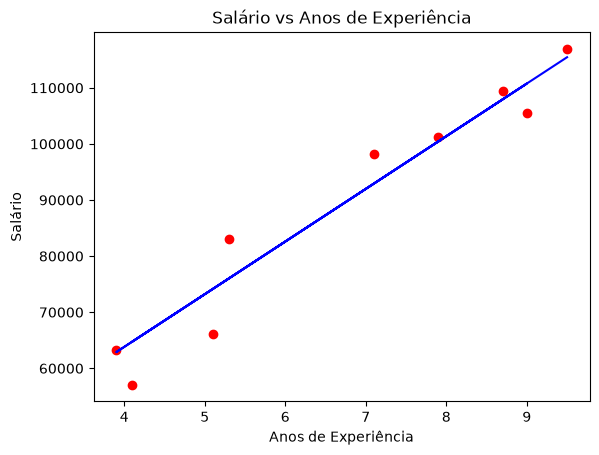

In [17]:
plt.scatter(X_teste, y_teste, color = 'red')
plt.plot(X_teste, y_prev, color = 'blue')
plt.title('Salário vs Anos de Experiência')
plt.xlabel('Anos de Experiência')
plt.ylabel('Salário')
plt.show()

### Avaliando os Resultados

In [18]:
from sklearn.metrics import mean_squared_error as mse
from math import sqrt

## 4. Medição dos resultados

### Calculando o RMSE

In [19]:
erro = sqrt(mse(y_teste, y_prev))

In [20]:
erro

5115.91763964267

### Calculando o R^2

In [21]:
from sklearn.metrics import r2_score as r2

In [22]:
erro = r2(y_teste, y_prev)

In [24]:
erro

0.9404887420519176